100.0%


max |dw1 diff| = 2.3283064365386963e-10
max |dw2 diff| = 1.1175870895385742e-08
Epoch 1/10  loss 1.9857  train acc 35.20%  test acc 35.02%
Epoch 2/10  loss 1.7898  train acc 38.92%  test acc 38.71%
Epoch 3/10  loss 1.7215  train acc 41.12%  test acc 40.36%
Epoch 4/10  loss 1.6792  train acc 42.62%  test acc 42.11%
Epoch 5/10  loss 1.6469  train acc 43.67%  test acc 42.61%
Epoch 6/10  loss 1.6195  train acc 44.90%  test acc 43.06%
Epoch 7/10  loss 1.5959  train acc 45.77%  test acc 44.26%
Epoch 8/10  loss 1.5733  train acc 46.35%  test acc 44.43%
Epoch 9/10  loss 1.5539  train acc 46.97%  test acc 44.81%
Epoch 10/10  loss 1.5354  train acc 47.81%  test acc 45.65%


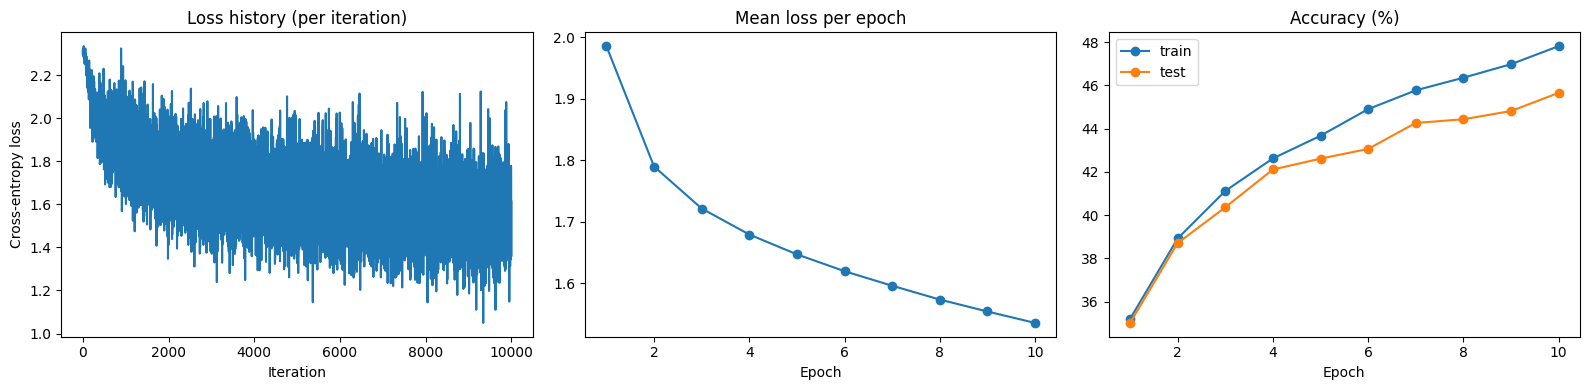

Training accuracy: 47.81%
Test accuracy:     45.65%


In [3]:
# %% [markdown]
# # Q1: Two-layer dense network (100 sigmoid hidden nodes) with cross-entropy, manual backprop
# Changes vs Listing 1: (a) hidden layer of 100 nodes + sigmoid, (b) softmax cross-entropy loss, (c) 10 epochs.

# %%
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)

# %% 1. Data loading (num_workers=0 avoids multiprocessing problems on Windows/Jupyter)
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# %% 2. Parameters
Din = 3 * 32 * 32      # input size
H = 100                # (a) hidden nodes
K = 10                 # classes
std = 1e-2             # 1e-5 (single-layer listing) is too small for two layers: gradients vanish

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

epochs = 10            # (c)
lr = 5e-2
lr_decay = 0.95
reg = 0.0              # L2 regularisation strength

# %% Helper functions
def forward(x):
    z1 = x.mm(w1) + b1
    h = torch.sigmoid(z1)          # (a) sigmoid activation
    logits = h.mm(w2) + b2
    return h, logits

def cross_entropy(logits, labels):
    """(b) softmax + cross-entropy, averaged over the batch."""
    log_probs = torch.log_softmax(logits, dim=1)
    return -log_probs[torch.arange(len(labels)), labels].mean()

def evaluate(loader):
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, logits = forward(x)
            loss_sum += cross_entropy(logits, labels).item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            total += len(labels)
    return 100 * correct / total, loss_sum / total

# %% Optional: gradient check of the manual backprop against autograd (one batch)
inputs, labels = next(iter(trainloader))
x = inputs.view(inputs.shape[0], -1)
N = x.shape[0]
h, logits = forward(x)
probs = torch.softmax(logits, dim=1)
dlogits = (probs - nn.functional.one_hot(labels, K).float()) / N
dw2_manual = h.t().mm(dlogits)
dz1 = dlogits.mm(w2.t()) * h * (1 - h)
dw1_manual = x.t().mm(dz1)

w1a, w2a = w1.clone().requires_grad_(), w2.clone().requires_grad_()
loss_a = cross_entropy(torch.sigmoid(x.mm(w1a) + b1).mm(w2a) + b2, labels)
loss_a.backward()
print("max |dw1 diff| =", (w1a.grad - dw1_manual).abs().max().item())
print("max |dw2 diff| =", (w2a.grad - dw2_manual).abs().max().item())

# %% 3. Training loop
loss_history = []
train_acc_hist, test_acc_hist, epoch_loss_hist = [], [], []

for t in range(epochs):
    running_loss = 0.0
    for i, (inputs, labels) in enumerate(trainloader):
        Ntr = inputs.shape[0]
        x = inputs.view(Ntr, -1)
        y_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, logits = forward(x)
        loss = cross_entropy(logits, labels) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation (manual)
        probs = torch.softmax(logits, dim=1)
        dlogits = (probs - y_onehot) / Ntr           # dL/dlogits for softmax + CE
        dw2 = h.t().mm(dlogits) + 2 * reg * w2
        db2 = dlogits.sum(dim=0)
        dh = dlogits.mm(w2.t())
        dz1 = dh * h * (1 - h)                       # sigmoid derivative
        dw1 = x.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w2 -= lr * dw2
        b2 -= lr * db2
        w1 -= lr * dw1
        b1 -= lr * db1

    lr *= lr_decay
    tr_acc, _ = evaluate(trainloader)
    te_acc, _ = evaluate(testloader)
    epoch_loss_hist.append(running_loss / len(trainloader))
    train_acc_hist.append(tr_acc)
    test_acc_hist.append(te_acc)
    print(f"Epoch {t + 1}/{epochs}  loss {epoch_loss_hist[-1]:.4f}  "
          f"train acc {tr_acc:.2f}%  test acc {te_acc:.2f}%")

# %% 4. Plots
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(loss_history); ax[0].set_title('Loss history (per iteration)')
ax[0].set_xlabel('Iteration'); ax[0].set_ylabel('Cross-entropy loss')
ax[1].plot(range(1, epochs + 1), epoch_loss_hist, marker='o'); ax[1].set_title('Mean loss per epoch')
ax[1].set_xlabel('Epoch')
ax[2].plot(range(1, epochs + 1), train_acc_hist, marker='o', label='train')
ax[2].plot(range(1, epochs + 1), test_acc_hist, marker='o', label='test')
ax[2].set_title('Accuracy (%)'); ax[2].set_xlabel('Epoch'); ax[2].legend()
plt.tight_layout(); plt.show()

# %% 5. Final accuracies
train_acc, _ = evaluate(trainloader)
test_acc, _ = evaluate(testloader)
print(f"Training accuracy: {train_acc:.2f}%")
print(f"Test accuracy:     {test_acc:.2f}%")